# 53 · MC와 TD: 타깃의 길이와 bootstrap을 읽기

📎 **이번 질문** · 배달이 끝날 때까지 보상을 기다릴까요, 한 번 움직인 뒤 현재 가치 추정으로 나머지를 이어 붙일까요?

고정 정책의 가치를 배웁니다. 52번처럼 네 상태를 쓰되, 이번에는 최대 세 전이 안에 종료하는 **새 작은 환경**으로 모든 경로를 열거합니다. 타깃 하나의 편향·분산을 정확히 계산하고, 실제 경로를 받아 표 V를 갱신한 결과는 별도로 확인합니다.

- 준비물: [27 Monte Carlo](../04_생성/27_monte_carlo_gradients.ipynb), [52 MDP·Bellman](52_mdp_bellman.ipynb).
- 도착점: MC return, TD 오차, n-step과 유한 λ-return, 종료/수집 제한, 고정 타깃과 실제 가치 학습의 차이를 구현합니다.
- NumPy·CPU만 사용합니다. 행동 정책은 고정되어 있고 이번에는 정책을 개선하지 않습니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 식·구현 | 타깃이 쓰는 보상 개수와 V의 시점을 적습니다 |
| 🔍 확인 | 그림·검산 | 경로 통계와 학습 오차를 구분합니다 |
| 📎 참고 | 용어·코드 | 새 규약을 확인합니다 |
| ✏️ 연습 | 한두 줄 구현 | 독립 손계산과 대조합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. MC는 종료까지 관측한 보상, TD는 한 보상과 현재 V, n-step은 그 사이를 씁니다.
2. 유한 λ-return의 마지막 가중치는 λ의 남은 질량입니다. 모든 타깃에 같은 고정 V를 써야 아래의 두 구현을 항등식으로 비교할 수 있습니다.
3. 타깃 분포의 편향·분산과 실제 학습된 V의 seed별 오차는 다른 실험입니다. 종료를 단순 수집 제한과 혼동하지 않습니다.

| 기호 | shape | 뜻 |
|---|---|---|
| p,next,r | `(S,O)` | 상태별 결과 O개의 확률·다음 상태·보상 |
| states,rewards | `(T+1,),(T,)` | 한 경로의 상태와 전이 보상 |
| V,G | `(S,),(T,)` | 고정한 가치 표·경로 시점별 타깃 |
| 학습 기록 | `(방법,seed,episode,S)` | 같은 경로를 쓴 독립 실행의 갱신 기록 |

[전체 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/mc_td_plots.py)

In [1]:
# 준비 셀: 계산과 그림 검산 부품입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.utils import setup_plots, run_check
from src.utils.mc_td_plots import (
    plot_mc_path, plot_td_update, plot_lambda_weights, plot_target_distribution,
    plot_prediction_protocol, plot_prediction_learning, plot_prediction_final,
)
setup_plots()
print('고정 정책 예측 · 상태0 시작 · 상태3 종료 · 최대3전이')

고정 정책 예측 · 상태0 시작 · 상태3 종료 · 최대3전이


## 🔑 1. 끝까지 관측한 return으로 가치를 배웁니다

**이 절에서 가져갈 것:** MC 타깃은 완료한 경로의 실제 보상 합이며, 경로 평균의 정확한 기대값을 열거할 수 있습니다.

현재 배달 정책을 바꾸지 않고 가치만 알고 싶습니다. 행동을 정책으로 평균한 뒤의 상태 전이·보상 분포를 직접 적습니다.

> **용어**
>
> - **MRP(Markov reward process)**는 정책을 고정한 뒤의 상태·보상 과정입니다. 별도의 행동 선택 축을 이미 평균했습니다.
> - **Monte Carlo(MC) 가치 예측**은 실제 종료까지 받은 return을 타깃으로 V를 갱신하는 방법입니다.
> - **첫 방문·모든 방문**은 한 episode에서 같은 상태를 처음 만났을 때만 쓸지, 만날 때마다 쓸지의 구분입니다. 이 환경은 되돌아가지 않으므로 둘이 같습니다.

각 결과의 확률은 1/2입니다. 같은 종료 상태에 도착해도 보상이 다를 수 있으므로 결과 두 개를 합쳐 없애지 않습니다.

| 현재 상태 | 결과0 `(다음 상태,보상)` | 결과1 |
|---|---|---|
| 0 시작 | (1,0) | (2,.4) |
| 1 다리 | (2,−.2) | (3,1) |
| 2 우회 | (3,0) | (3,2) |
| 3 종료 | (3,0) | (3,0) |

$$G_t=R_{t+1}+\gamma R_{t+2}+\cdots+\gamma^{T-t-1}R_T,
\qquad V(S_t)\leftarrow V(S_t)+\alpha[G_t-V(S_t)].$$

γ=0.9입니다. 경로 0→1→2→3, 보상 [0,−.2,2]의 return은 [1.44,1.6,2]입니다. 실제 타깃은 같은 상태에서도 받은 경로에 따라 달라집니다. α를 방문 횟수의 역수로 두면 표본평균이고, 마지막 실험은 모든 방법에서 고정 α=.1을 사용합니다.

> **코드** · `reversed(range(T))`는 T−1부터 0까지 거꾸로 순회합니다. 보상 길이 T보다 상태열이 하나 더 길어야 마지막 도착 상태를 저장할 수 있습니다. `np.linalg.solve(A,b)`는 역행렬을 직접 만들지 않고 Av=b를 풉니다. `gamma**np.arange(T)`는 할인 지수 0부터 T−1까지를 배열로 만듭니다.

In [2]:
gamma = 0.9
path_states = np.array([0,1,2,3])
path_rewards = np.array([0.0,-0.2,2.0])
path_returns = np.zeros(3)
for start in range(3):
    for step in range(start,3):
        path_returns[start] += gamma**(step-start) * path_rewards[step]
print('손계산 return [1.44,1.6,2]:',path_returns)

손계산 return [1.44,1.6,2]: [1.44 1.6  2.  ]


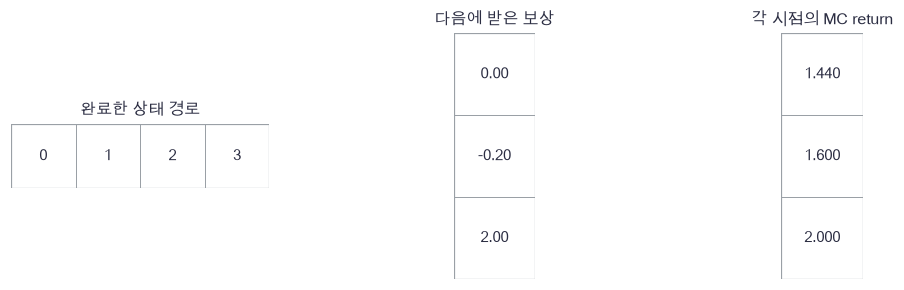

In [3]:
plot_mc_path(path_states, path_rewards, path_returns)

🔍 **확인** · 첫 상태의 타깃은 마지막 보상 2만이 아니라 중간 비용 −.2와 할인까지 포함한 1.44입니다. 종료 보상까지 포함하고 종료 이후의 가치는 0으로 둡니다.

In [4]:
def make_prediction_process():
    """고정 정책 아래 4상태·상태별2결과의 MRP. 확률·다음상태·보상:(S,2), terminal:(S,)."""
    probability = np.full((4,2),0.5)
    next_state = np.array([[1,2],[2,3],[3,3],[3,3]])
    reward = np.array([[0.0,0.4],[-0.2,1.0],[0.0,2.0],[0.0,0.0]])
    terminal = np.array([False,False,False,True])
    return probability,next_state,reward,terminal

In [5]:
def mc_returns(rewards,gamma):
    """진짜 종료까지 관측한 보상의 역순 return. rewards:(T,) → 각 시점의 G:(T,)."""
    returns = np.zeros(len(rewards))
    value = 0.0
    for step in reversed(range(len(rewards))):
        value = rewards[step] + gamma*value
        returns[step] = value
    return returns

In [6]:
def exact_prediction_value(probability,next_state,reward,terminal,gamma):
    """결과를 다음 상태별로 합친 뒤 Bellman 선형 시스템을 풉니다. → V:(S,)."""
    transition = np.zeros((len(terminal),len(terminal)))
    mean_reward = np.zeros(len(terminal))
    for state in range(len(terminal)):
        for outcome in range(probability.shape[1]):
            destination = next_state[state,outcome]
            transition[state,destination] += probability[state,outcome]*(1-terminal[destination])
            mean_reward[state] += probability[state,outcome]*reward[state,outcome]
    return np.linalg.solve(np.eye(len(terminal))-gamma*transition,mean_reward)

In [7]:
# 쓰는 것: gamma, path_rewards (위 절의 정의·실행 셀)
probability,next_state,reward,terminal = make_prediction_process()
truth = exact_prediction_value(probability,next_state,reward,terminal,gamma)
np.testing.assert_allclose(mc_returns(path_rewards,gamma),[1.44,1.6,2.0])  # 검산: 역순 재귀=앞쪽 보상 합 손계산
np.testing.assert_allclose(truth,[1.0325,0.85,1.0,0.0])  # 검산: V2=1, V1=(−.2+.9)/2+.5, V0=.9V1/2+(.4+.9)/2
np.testing.assert_allclose(probability.sum(axis=1),1.0)  # 검산: 결과 확률 합=1
print('완료 경로 MC와 Bellman 선형 정확해 통과:',truth)

완료 경로 MC와 Bellman 선형 정확해 통과: [1.0325 0.85   1.     0.    ]


### ✏️ 연습 1 · 완료 경로의 return

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

보상 배열을 처음 시점 기준으로 할인해 더하세요.

In [8]:
def exercise_mc(rewards, gamma):
    """완료 경로의 return의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [9]:
def check_mc(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.,-.2,2.]),.9),1.44)  # 검산: 0−.18+1.62
    print('완료 경로 MC 합 통과')

run_check(check_mc,exercise_mc,hint='첫 보상 지수는0입니다.')

☐ exercise_mc: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 첫 보상 지수는0입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.sum(rewards * gamma**np.arange(len(rewards)))
```

</details>

## 🔑 2. 한 전이와 현재 가치로 TD 오차를 만듭니다

**이 절에서 가져갈 것:** TD 타깃은 관측 보상 하나와 다음 상태의 고정된 현재 가치이며, 오차는 타깃에서 현재 값을 뺀 것입니다.

배달이 끝나기 전이라도 한 번 움직인 뒤 V를 갱신할 수 있습니다. 다음 상태에서 받을 보상 전체를 아직 모르므로 V의 현재 추정을 사용합니다.

$$Y_t^{TD}=R_{t+1}+\gamma(1-terminated_{t+1})V(S_{t+1}),\qquad
\delta_t=Y_t^{TD}-V(S_t),\qquad V(S_t)\leftarrow V(S_t)+\alpha\delta_t.$$

> **용어**
>
> - **TD(temporal difference)**는 지금의 가치 추정과 한 단계 뒤 보상·가치 추정 사이 차이로 배우는 방법입니다.
> - **bootstrap**은 타깃 일부를 현재 추정 V로 채우는 것입니다. 그 추정이 틀리면 타깃의 기대값에도 오차가 들어올 수 있습니다.
> - **고정 타깃**은 한 갱신에서 타깃을 계산한 뒤, 그 숫자를 바꾸지 않고 현재 예측을 이동시키는 규약입니다. 이 표 기반 단원에는 신경망 미분이 없습니다.

V=(.2,.4,.5,99)라고 합시다. 0→1에서 보상0을 받으면 타깃 .36, TD 오차 .16입니다. 2→종료에서 보상2를 받으면 terminal 마스크가 99를 제거해 타깃2, 오차1.5입니다.

In [10]:
# 쓰는 것: gamma (위 절의 정의·실행 셀)
frozen_values = np.array([0.2,0.4,0.5,99.0])
td_current = np.array([frozen_values[0],frozen_values[2]])
td_rewards = np.array([0.0,2.0])
td_next = np.array([frozen_values[1],0.0])
td_targets = td_rewards + gamma*td_next
td_errors = td_targets-td_current

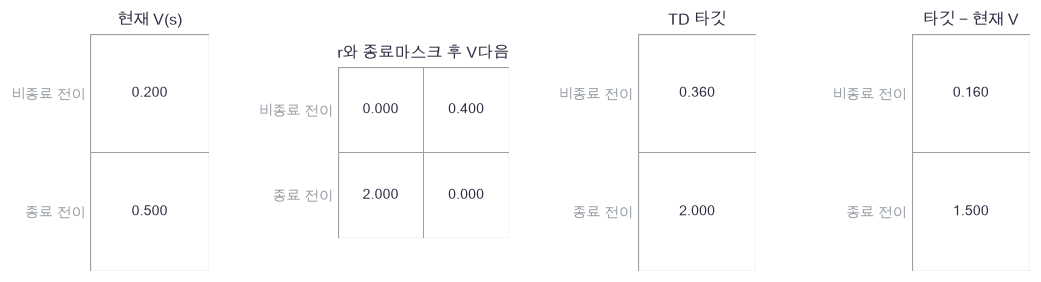

In [11]:
plot_td_update(td_current, td_next, td_rewards, td_targets, td_errors)

🔍 **확인** · 종료로 들어갈 때 보상2는 남기고 다음 가치만 막습니다. 단순 수집 제한으로 관측이 멈춘 전이는 terminal로 바꾸지 않습니다. 그 경우에는 다음 상태의 V를 계속 사용합니다.

In [12]:
def td_target(reward,next_state,terminated,values,gamma):
    """한 전이의 r+γ(1−terminated)V(s'). terminated는 수집 제한이 아닌 실제 환경 종료입니다."""
    return float(reward + gamma*(1.0-float(terminated))*values[next_state])

In [13]:
# 쓰는 것: gamma, truth (위 절의 정의·실행 셀)
np.testing.assert_allclose(td_target(0.0,1,False,frozen_values,gamma),0.36)  # 검산: 비종료 타깃0+.9×.4
np.testing.assert_allclose(td_target(2.0,3,True,frozen_values,gamma),2.0)  # 검산: 종료 상태99를 차단하고 보상2 보존
new_value = frozen_values[0] + 0.1*td_errors[0]
np.testing.assert_allclose(new_value,0.216)  # 검산: .2+.1×.16
np.testing.assert_allclose(td_target(0.0,1,False,truth,gamma),0.765)  # 검산: 정확한 다음 가치로 만든 한 전이 타깃
print('TD 타깃·오차·한 번 갱신·종료 마스크 통과')

TD 타깃·오차·한 번 갱신·종료 마스크 통과


### ✏️ 연습 2 · TD 오차를 반환합니다

target과 현재 prediction이 주어졌습니다.

In [14]:
def exercise_td_error(target, prediction):
    """TD 오차를 반환합니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return error

In [15]:
def check_td_error(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.36,2.]),np.array([.2,.5])),[.16,1.5])  # 검산: 두 전이의 타깃−예측
    print('TD 오차 통과')

run_check(check_td_error,exercise_td_error,hint='업데이트는 이 오차에 alpha를 곱해 더합니다.')

☐ exercise_td_error: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 업데이트는 이 오차에 alpha를 곱해 더합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
error = target - prediction
```

</details>

## 🔑 3. n-step과 유한 λ-return을 연결합니다

**이 절에서 가져갈 것:** 여러 보상 뒤 bootstrap하는 n-step을 섞되, 마지막 λ 가중치의 남은 질량을 보존합니다.

한 전이만 쓰거나 끝까지 기다리는 사이에서 타깃 길이를 고를 수 있습니다. 경로에 남은 전이가 m개이고 n≤m이면

$$G_t^{(n)}=\sum_{j=0}^{n-1}\gamma^jR_{t+j+1}
+\gamma^n\mathbf1[\text{그 지점이 진짜 종료 아님}]V(S_{t+n}).$$

n이 남은 경로보다 크면 관측한 끝까지만 합하고, 그 끝이 **수집 제한**이면 V를 붙입니다. 완료 경로에서 n≥m은 MC return입니다.

$$G_t^\lambda=(1-\lambda)\sum_{n=1}^{m-1}\lambda^{n-1}G_t^{(n)}
+\lambda^{m-1}G_t^{(m)}.$$

λ∈[0,1]이며 가중치 합은1입니다. 마지막 항에도 1−λ를 곱하면 합이1보다 작아집니다. λ=0은 한 단계, λ=1은 완료 경로의 MC입니다. 마지막이 수집 제한이면 λ=1도 관측 보상 끝에 V가 붙은 타깃입니다.

> **용어** · **n-step**은 n개 보상을 관측한 뒤 남은 가치를 붙이는 방식입니다. **forward λ-return**은 여러 길이 타깃의 가중평균입니다. 여기서는 한 경로의 타깃을 모두 만들 때 V를 고정하며, 매 스텝 V를 바꾸는 온라인 eligibility trace 알고리즘과 동일하다고 주장하지 않습니다.

In [16]:
# 쓰는 것: frozen_values, gamma, path_returns, path_rewards (위 절의 정의·실행 셀)
step_targets = np.array([gamma*frozen_values[1],
                         path_rewards[0]+gamma*path_rewards[1]+gamma**2*frozen_values[2],
                         path_returns[0]])
lam = 0.7
lambda_weights = np.array([1-lam,(1-lam)*lam,lam**2])
lambda_contributions = lambda_weights*step_targets
print('n-step 타깃:',step_targets,'· λ 혼합:',lambda_contributions.sum())

n-step 타깃: [0.36  0.225 1.44 ] · λ 혼합: 0.86085


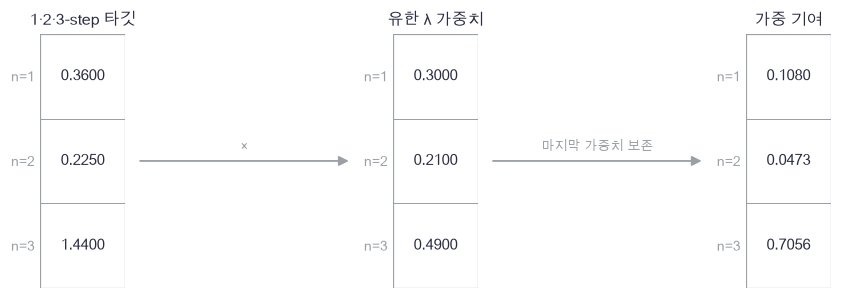

In [17]:
plot_lambda_weights(step_targets, lambda_weights, lambda_contributions)

🔍 **확인** · 세 가중치는 .3·.21·.49입니다. 마지막 .49에는 1−λ가 추가로 붙지 않습니다. 같은 고정 V를 쓰면 역순 재귀

$$G_t^\lambda=R_{t+1}+\gamma[(1-\lambda)V(S_{t+1})+\lambda G_{t+1}^\lambda]$$

로도 계산할 수 있습니다. 단, 마지막 terminal에서는 두 미래 항이 0이고 수집 제한이면 마지막 값으로 V를 넣어 시작합니다.

> **코드** · `min(start+n,T)`는 경로 밖 보상을 읽지 않게 제한합니다. `states[-1]`은 관측한 마지막 상태입니다. `range(1,m+1)`은 길이 1부터 m까지입니다. `[f(n) for n in items]`는 각 원소에 함수를 적용한 결과 목록입니다.

In [18]:
def n_step_target(states,rewards,terminated,values,start,n,gamma):
    """고정 V의 n-step 타깃. states:(T+1,), rewards:(T,); 수집 끝이 비종료면 bootstrap합니다."""
    stop = min(start+n,len(rewards))
    target = 0.0
    for index in range(start,stop):
        target += gamma**(index-start)*rewards[index]
    if stop < len(rewards) or not terminated:
        target += gamma**(stop-start)*values[states[stop]]
    return float(target)

In [19]:
def lambda_target(states,rewards,terminated,values,start,lam,gamma):
    """유한 경로의 forward λ 타깃: 중간 (1−λ)λ^(n−1), 마지막 λ^(m−1)."""
    remaining = len(rewards)-start
    target = 0.0
    for n in range(1,remaining+1):
        weight = lam**(n-1)
        if n < remaining:
            weight *= 1.0-lam
        target += weight*n_step_target(states,rewards,terminated,values,start,n,gamma)
    return float(target)

In [20]:
def lambda_returns_backward(states,rewards,terminated,values,lam,gamma):
    """같은 고정 V를 쓰는 λ 반환의 역순 재귀. 온라인 eligibility trace 알고리즘은 아닙니다."""
    returns = np.zeros(len(rewards))
    value = 0.0 if terminated else float(values[states[-1]])
    for step in reversed(range(len(rewards))):
        continuation = 0.0 if terminated and step==len(rewards)-1 else values[states[step+1]]
        value = rewards[step] + gamma*((1.0-lam)*continuation + lam*value)
        returns[step] = value
    return returns

In [21]:
# 쓰는 것: frozen_values, gamma, lambda_weights, path_rewards, path_states, step_targets (위 절의 정의·실행 셀)
computed_targets = np.array([n_step_target(path_states,path_rewards,True,frozen_values,0,n,gamma) for n in [1,2,3]])
np.testing.assert_allclose(computed_targets,step_targets)  # 검산: n-step 함수=직접1·2·3단계 계산
np.testing.assert_allclose(lambda_target(path_states,path_rewards,True,frozen_values,0,0.7,gamma),0.86085)  # 검산: .3×.36+.21×.225+.49×1.44
np.testing.assert_allclose(lambda_weights.sum(),1.0)  # 검산: 유한 λ 마지막 잔여 가중치
for parameter in [0.0,0.7,1.0]:
    forward = np.array([lambda_target(path_states,path_rewards,True,frozen_values,t,parameter,gamma) for t in range(3)])
    backward = lambda_returns_backward(path_states,path_rewards,True,frozen_values,parameter,gamma)
    np.testing.assert_allclose(forward,backward)  # 검산: 같은 고정 V의 forward 혼합=역순 λ 재귀
truncated_states = np.array([0,1])
truncated_rewards = np.array([0.0])
np.testing.assert_allclose(n_step_target(truncated_states,truncated_rewards,False,frozen_values,0,9,gamma),0.36)  # 검산: 관측끝이 비종료면 n이 커도 V를 붙임
np.testing.assert_allclose(lambda_returns_backward(truncated_states,truncated_rewards,False,frozen_values,1.0,gamma),[0.36])  # 검산: λ1도 수집 제한에서는 bootstrap 보존
print('n-step·λ 양끝·두 λ 구현·수집 제한 검산 통과')

n-step·λ 양끝·두 λ 구현·수집 제한 검산 통과


### ✏️ 연습 3 · 유한 λ의 마지막 가중치

길이 m인 완료 경로의 마지막 타깃 가중치를 구하세요.

In [22]:
def exercise_last_weight(lam, m):
    """유한 λ의 마지막 가중치의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return weight

In [23]:
def check_last_weight(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(.7,3),.49)  # 검산: 마지막 남은 질량=.7²
    np.testing.assert_allclose(fn(0.0,1),1.0)  # 검산: 길이1은 유일한 타깃의 가중치1
    print('마지막 lambda 질량 통과')

run_check(check_last_weight,exercise_last_weight,hint='마지막에는 1−lambda를 곱하지 않습니다.')

☐ exercise_last_weight: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 마지막에는 1−lambda를 곱하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
weight = lam**(m-1)
```

</details>

## 🔑 4. 타깃의 편향·분산을 모든 경로에서 계산합니다

**이 절에서 가져갈 것:** 고정한 V에 대해 타깃 분포를 정확히 열거하고, 그 통계를 학습된 V의 오차와 구분합니다.

한 경로에서 TD가 참값에 더 가까웠다는 이유만으로 분산이 작다고 말할 수 없습니다. 이 환경의 시작 상태에서 가능한 완전 종료 경로는 5개이므로, 각 경로 확률을 곱해 타깃의 평균·분산을 정확히 계산할 수 있습니다.

$$\bar Y=\sum_\omega p_\omega Y_\omega,\quad
\operatorname{Var}(Y)=\sum_\omega p_\omega(Y_\omega-\bar Y)^2,\quad
bias=\bar Y-V^\pi(0),$$
$$\operatorname{MSE}(Y)=\sum_\omega p_\omega(Y_\omega-V^\pi(0))^2
=\operatorname{Var}(Y)+bias^2.$$

ω는 완전 경로 하나입니다. 여기의 분산은 **타깃 한 개**의 분산입니다. 표본 평균의 SE나 학습된 V의 seed SD와 다릅니다. 먼저 앞 절의 부정확한 고정 V를 쓰고, 다음에는 정확한 V를 넣어 타깃의 기대값이 같은지 확인합니다.

> **용어** · **편향(bias)**은 타깃의 반복 기대값과 참 가치의 차이입니다. **분산**은 그 기대값 주위에서 경로마다 타깃이 흔들리는 크기입니다. **MSE**는 참 가치에서의 제곱 오차 기대값입니다.
>
> **코드** · `[f(n) for n in items]`는 각 원소에 함수를 적용해 결과 목록을 만듭니다. `np.column_stack`은 길이가 같은 배열들을 열로 붙이고 `p[:,None]`은 경로 확률에 열 축을 추가해 방법별 타깃에 곱합니다. 아래 경로 열거 함수는 상태가 증가하는 acyclic 환경에서만 사용합니다. 순환 환경에 그대로 재귀 열거하면 끝나지 않을 수 있습니다.

In [24]:
# 쓰는 것: frozen_values, gamma, lam, lambda_target, mc_returns, n_step_target, truth (위 절의 정의·실행 셀)
path_probabilities = np.array([0.125,0.125,0.25,0.25,0.25])
explicit_states = [np.array([0,1,2,3]),np.array([0,1,2,3]),np.array([0,1,3]),np.array([0,2,3]),np.array([0,2,3])]
explicit_rewards = [np.array([0.,-.2,0.]),np.array([0.,-.2,2.]),np.array([0.,1.]),np.array([.4,0.]),np.array([.4,2.])]
method_names = ['MC','TD0','2-step','λ=.7']
example_targets = np.zeros((5,4))
for index in range(5):
    states,rewards = explicit_states[index],explicit_rewards[index]
    example_targets[index] = [mc_returns(rewards,gamma)[0],
        n_step_target(states,rewards,True,frozen_values,0,1,gamma),
        n_step_target(states,rewards,True,frozen_values,0,2,gamma),
        lambda_target(states,rewards,True,frozen_values,0,lam,gamma)]
example_mean = np.sum(path_probabilities[:,None]*example_targets,axis=0)
example_variance = np.sum(path_probabilities[:,None]*(example_targets-example_mean)**2,axis=0)
example_bias = example_mean-truth[0]
example_mse = np.sum(path_probabilities[:,None]*(example_targets-truth[0])**2,axis=0)
example_moments = np.column_stack([example_mean,example_variance,example_bias,example_mse])

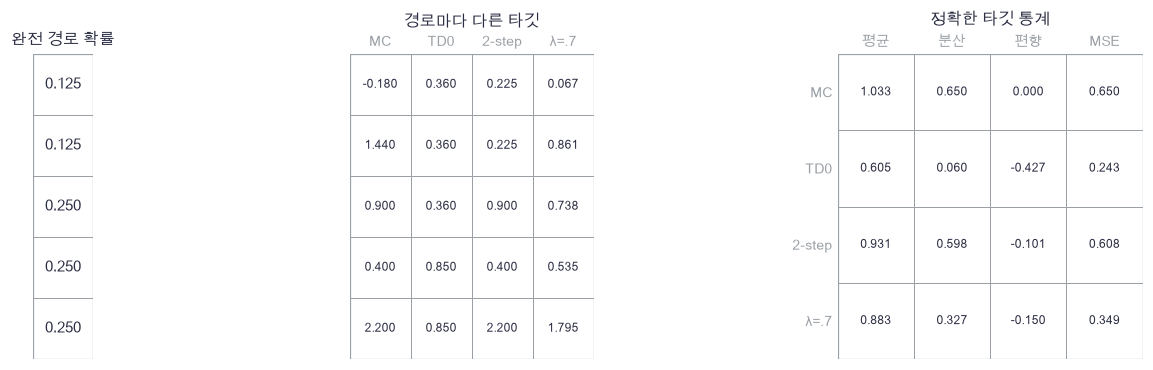

In [25]:
plot_target_distribution(path_probabilities, example_targets, example_moments, method_names)

🔍 **확인** · MC 열의 기대값은 정확한 V와 같지만 경로별 값은 넓게 퍼집니다. 현재 V가 부정확한 TD·다단계 타깃에는 기대값 오차가 들어갈 수 있습니다. 어느 타깃의 MSE가 작은지는 환경·현재 V에 따라 달라지므로 보편적 우열로 일반화하지 않습니다.

In [26]:
def enumerate_paths(probability,next_state,reward,terminal,start=0):
    """이 acyclic 환경의 완전 종료 경로를 전수열거합니다. 각 항은 (경로확률,상태열,보상열)."""
    paths = []
    def visit(state,mass,states,rewards):
        """현재 상태의 가능한 결과 둘을 각각 이어 갑니다."""
        if terminal[state]:
            paths.append((mass,np.array(states),np.array(rewards)))
            return
        for outcome in range(probability.shape[1]):
            destination = int(next_state[state,outcome])
            visit(destination,mass*probability[state,outcome],states+[destination],rewards+[reward[state,outcome]])
    visit(start,1.0,[start],[])
    return paths

In [27]:
def target_moments(weights,targets,truth):
    """유한 경로 분포의 타깃 평균·분산·편향·MSE. 경로 가중치의 정확한 합으로 계산합니다."""
    average = np.sum(weights*targets)
    variance = np.sum(weights*(targets-average)**2)
    bias = average-truth
    mse = np.sum(weights*(targets-truth)**2)
    return np.array([average,variance,bias,mse])

In [28]:
# 쓰는 것: example_bias, example_mean, example_mse, example_variance, explicit_rewards, explicit_states, next_state, path_probabilities, probability, reward, terminal, truth (위 절의 정의·실행 셀)
all_paths = enumerate_paths(probability,next_state,reward,terminal)
assert len(all_paths)==5, '이 acyclic 환경의 시작 경로는5개이어야 합니다'
np.testing.assert_allclose(np.array([item[0] for item in all_paths]),path_probabilities)  # 검산: 재귀 전수열거 경로 확률=직접 나열
for index in range(5):
    np.testing.assert_array_equal(all_paths[index][1],explicit_states[index])  # 검산: 열거한 상태 경로
    np.testing.assert_allclose(all_paths[index][2],explicit_rewards[index])  # 검산: 열거한 보상 경로
np.testing.assert_allclose(example_mse,example_variance+example_bias**2)  # 검산: 타깃의 정확한 편향²+분산 분해
np.testing.assert_allclose(example_mean[0],truth[0])  # 검산: 모든 종료 경로 MC 기대값=Bellman 정확해
print('경로 전수열거·MC 기대값·타깃 MSE 분해 통과')

경로 전수열거·MC 기대값·타깃 MSE 분해 통과


In [29]:
# 쓰는 것: gamma, lam, lambda_target, mc_returns, n_step_target, path_probabilities, truth (위 절의 정의·실행 셀)
correct_value_targets = np.zeros((5,4))
for index,(mass,states,rewards) in enumerate(all_paths):
    correct_value_targets[index] = [mc_returns(rewards,gamma)[0],
        n_step_target(states,rewards,True,truth,0,1,gamma),
        n_step_target(states,rewards,True,truth,0,2,gamma),
        lambda_target(states,rewards,True,truth,0,lam,gamma)]
correct_moments = []
for method in range(4):
    correct_moments.append(target_moments(path_probabilities,correct_value_targets[:,method],truth[0]))
correct_moments = np.array(correct_moments)
np.testing.assert_allclose(correct_moments[:,0],truth[0],atol=1e-14)  # 검산: 정확 V를 쓰면 네 타깃의 열거 기대값은 동일
print('정확 V에서 [평균,분산,편향,MSE]:',np.round(correct_moments,6))

정확 V에서 [평균,분산,편향,MSE]: [[1.0325   0.649694 0.       0.649694]
 [1.0325   0.071556 0.       0.071556]
 [1.0325   0.485669 0.       0.485669]
 [1.0325   0.313854 0.       0.313854]]


### ✏️ 연습 4 · 정확한 경로 분포의 편향

경로별 확률과 타깃을 받아 참값과의 기대 차이를 구하세요.

In [30]:
def exercise_bias(weights, targets, truth):
    """정확한 경로 분포의 편향의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return bias

In [31]:
def check_bias(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.25,.75]),np.array([0.,2.]),1.0),.5)  # 검산: 타깃기대1.5−참값1
    print('타깃 편향 통과')

run_check(check_bias,exercise_bias,hint='한 표본의 오차 대신 확률 가중 기대값을 먼저 구합니다.')

☐ exercise_bias: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 한 표본의 오차 대신 확률 가중 기대값을 먼저 구합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
bias = np.sum(weights * targets) - truth
```

</details>

## 🔑 5. 같은 episode에서 네 가지 가치 학습을 비교합니다

**이 절에서 가져갈 것:** 타깃의 정확한 분포 비교와 별도로 실제 V 갱신을 수행하고, 독립 실행 전체의 오차를 남깁니다.

각 방법을 0에서 시작해 같은 완료 episode 300개로 학습합니다. 독립 seed는 32개, γ=.9·α=.1·λ=.7을 미리 고정합니다. 비교 방법은 MC·TD(0)·2-step·λ-return입니다. α가 일정하므로 오래 학습해도 표본 흔들림이 완전히 사라진다는 보장은 없습니다.

한 episode의 타깃들을 만들 때 V를 복사해 고정하고, 타깃 계산이 모두 끝난 뒤 방문 상태만 $V\leftarrow V+\alpha(Y-V)$로 갱신합니다. 이 환경은 상태를 재방문하지 않아 각 상태가 한 episode에서 최대 한 번 갱신됩니다. 온라인 TD와 eligibility trace의 일반적 동일성을 주장하는 실험은 아닙니다.

$$\operatorname{RMSE}(\widehat V)=\sqrt{\frac13\sum_{s=0}^2(\widehat V(s)-V^\pi(s))^2}.$$

평가에는 환경 표에서 계산한 정확한 V만 사용하고 학습 갱신에는 넣지 않습니다. 추가로 별도의 2,000개 평가 경로의 MC 평균·SE도 출력합니다. 그 평가 경로로 α·λ를 선택하거나 V를 고치지 않습니다.

> **코드** · `frozen=values.copy()`는 타깃을 만드는 동안 이전 값이 변하지 않게 복사합니다. `rng.choice(O,p=probability[state])`는 현재 상태의 결과를 실제로 하나 뽑습니다. `np.stack`은 같은 모양의 기록을 새 축으로 쌓습니다.

In [32]:
# 쓰는 것: gamma, lam (위 절의 정의·실행 셀)
REPEATS,EPISODES = 32,300
alpha = 0.1
plan_values = np.zeros(3)
plan_targets = np.array([0.0,-0.2,2.0])
plan_updated = plan_values + alpha*(plan_targets-plan_values)
plan_settings = np.array([[REPEATS],[EPISODES],[alpha],[gamma],[lam]])

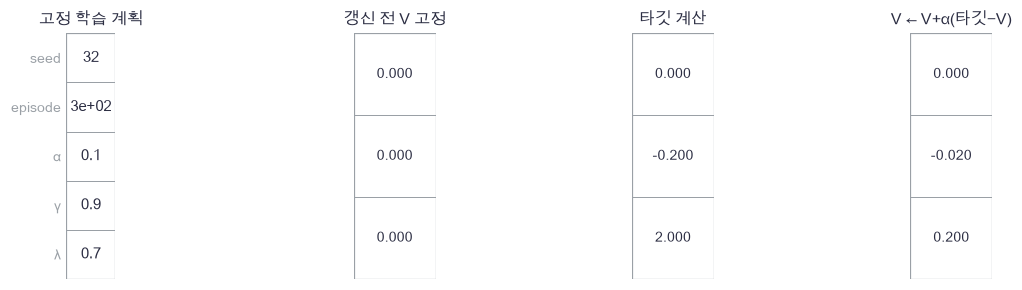

In [33]:
plot_prediction_protocol(plan_settings, plan_values, plan_targets, plan_updated)

🔍 **확인** · 보상을 나중에 받는 시작 상태는 첫 TD 타깃이 0일 수 있습니다. 미래 상태의 가치가 배우는 동안 앞 상태로 전파됩니다. 완전 MC는 같은 완료 경로의 마지막 보상을 첫 갱신부터 반영합니다. 정보 전파 속도와 표본 흔들림을 함께 보겠습니다.

In [34]:
def sample_prediction_episode(probability,next_state,reward,terminal,rng):
    """현재 고정 정책 MRP에서 실제 종료까지 표본 경로를 만듭니다. 최대3전이인 환경입니다."""
    state = 0
    states = [state]
    rewards = []
    while not terminal[state]:
        outcome = rng.choice(probability.shape[1],p=probability[state])
        rewards.append(reward[state,outcome])
        state = int(next_state[state,outcome])
        states.append(state)
    return np.array(states),np.array(rewards)

In [35]:
def train_predictor(episodes,method,gamma,alpha=0.1,lam=0.7):
    """같은 완료 episode들로 표 V를 갱신합니다. 한 episode의 모든 타깃은 갱신 전 V로 계산합니다."""
    # 쓰는 것: lambda_target, mc_returns, n_step_target (위 절의 정의·실행 셀)
    # 1. 모든 방법은 같은 0 초기값과 상수 학습률을 씁니다.
    values = np.zeros(4)
    history = [values.copy()]
    for states,rewards in episodes:
        frozen = values.copy()
        mc = mc_returns(rewards,gamma)
        targets = np.zeros(len(rewards))
        # 2. 타깃을 완성한 다음 해당 경로의 상태만 갱신합니다.
        for step in range(len(rewards)):
            if method=='MC':
                targets[step] = mc[step]
            elif method=='TD0':
                targets[step] = n_step_target(states,rewards,True,frozen,step,1,gamma)
            elif method=='2-step':
                targets[step] = n_step_target(states,rewards,True,frozen,step,2,gamma)
            elif method=='lambda':
                targets[step] = lambda_target(states,rewards,True,frozen,step,lam,gamma)
            else:
                raise ValueError('알 수 없는 타깃 방법입니다')
        for step in range(len(rewards)):
            state = states[step]
            values[state] += alpha*(targets[step]-values[state])
        history.append(values.copy())
    return values,np.array(history)

In [36]:
# 쓰는 것: gamma, path_rewards, path_states (위 절의 정의·실행 셀)
constant_episode = [(path_states,path_rewards)]
one_mc,one_history = train_predictor(constant_episode,'MC',gamma,alpha=1.0)
one_td,td_history = train_predictor(constant_episode,'TD0',gamma,alpha=1.0)
np.testing.assert_allclose(one_mc,[1.44,1.6,2.0,0.0])  # 검산: α1 MC 한 갱신은 완료 return
np.testing.assert_allclose(one_td,[0.0,-0.2,2.0,0.0])  # 검산: 0 초기값의 고정 한 단계 타깃
np.testing.assert_allclose(one_history[0],0.0)  # 검산: 기록한 초기 배열이 갱신 뒤에도 보존
print('실제 V 갱신·고정 타깃·초기 기록 보존 통과')

실제 V 갱신·고정 타깃·초기 기록 보존 통과


In [37]:
# 쓰는 것: EPISODES, REPEATS, alpha, gamma, lam, next_state, probability, reward, terminal (위 절의 정의·실행 셀)
methods = ['MC','TD0','2-step','lambda']
learning_histories = np.zeros((4,REPEATS,EPISODES+1,4))
for repeat in range(REPEATS):
    rng = np.random.default_rng(53100+repeat)
    episodes = []
    for episode in range(EPISODES):
        episodes.append(sample_prediction_episode(probability,next_state,reward,terminal,rng))
    for method_index,method in enumerate(methods):
        values,history = train_predictor(episodes,method,gamma,alpha,lam)
        learning_histories[method_index,repeat] = history
print('학습 완료: 4방법 × 32seed × 300episode · 방법끼리는 같은 경로')

학습 완료: 4방법 × 32seed × 300episode · 방법끼리는 같은 경로


In [38]:
# 쓰는 것: EPISODES, REPEATS, truth (위 절의 정의·실행 셀)
rmse_records = np.sqrt(np.mean((learning_histories[:,:,:,:3]-truth[:3])**2,axis=3))
mean_rmse = rmse_records.mean(axis=1)
se_rmse = rmse_records.std(axis=1,ddof=1) / np.sqrt(REPEATS)
mean_final_values = learning_histories[:,:,-1,:3].mean(axis=1)
episode_numbers = np.arange(EPISODES+1)

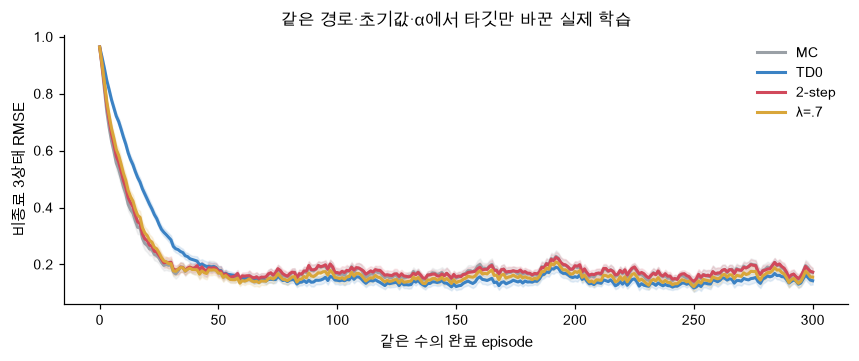

In [39]:
plot_prediction_learning(episode_numbers, mean_rmse, se_rmse, method_names)

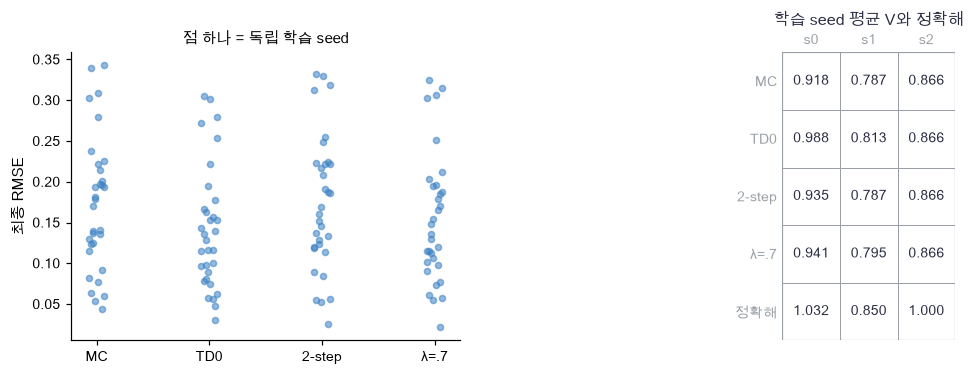

In [40]:
plot_prediction_final(method_names, rmse_records[:,:,-1], mean_final_values, truth[:3])

🔍 **확인** · 띠는 같은 시점의 32개 독립 학습 실행 평균 RMSE의 SE입니다. 전체 곡선의 동시 신뢰구간이 아닙니다. 아래 점들은 모든 seed의 마지막 오차이며 좋은 실행만 고르지 않았습니다. 타깃 분산 표의 순위가 유한 예산의 학습 RMSE 순위를 그대로 보장하지는 않습니다.

In [41]:
# 쓰는 것: gamma, learning_histories, mc_returns, method_names, next_state, probability, reward, sample_prediction_episode, terminal, truth (위 절의 정의·실행 셀)
evaluation_rng = np.random.default_rng(53999)
heldout_returns = np.zeros(2000)
for episode in range(len(heldout_returns)):
    states,rewards = sample_prediction_episode(probability,next_state,reward,terminal,evaluation_rng)
    heldout_returns[episode] = mc_returns(rewards,gamma)[0]
print('별도 평가 MC 평균:',heldout_returns.mean(),'SE:',heldout_returns.std(ddof=1)/np.sqrt(len(heldout_returns)),'정확값:',truth[0])
for index,name in enumerate(method_names):
    errors = rmse_records[index,:,-1]
    print(name,'최종 RMSE 평균/SD:',round(errors.mean(),4),round(errors.std(ddof=1),4),'범위:',np.round([errors.min(),errors.max()],4))
assert np.isfinite(learning_histories).all(), '모든 실제 학습값은 유한해야 합니다'
np.testing.assert_allclose(learning_histories[:,:,:,3],0.0)  # 검산: 종료 상태는 갱신하지 않아0 유지
print('유한값·종료 가치 보존 통과 · 방법의 우열은 관측 결과입니다')

별도 평가 MC 평균: 1.0227600000000001 SE: 0.01803163223561695 정확값: 1.0325
MC 최종 RMSE 평균/SD: 0.1719 0.0826 범위: [0.0442 0.3426]
TD0 최종 RMSE 평균/SD: 0.1427 0.0758 범위: [0.0301 0.3054]
2-step 최종 RMSE 평균/SD: 0.1732 0.083 범위: [0.025 0.332]
λ=.7 최종 RMSE 평균/SD: 0.1552 0.0801 범위: [0.0216 0.3251]
유한값·종료 가치 보존 통과 · 방법의 우열은 관측 결과입니다


### ✏️ 연습 5 · 타깃을 고정한 한 번의 가치 갱신

현재 value에서 고정 target 쪽으로 alpha만큼 이동하세요.

In [42]:
def exercise_update(value, target, alpha):
    """타깃을 고정한 한 번의 가치 갱신의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return updated

In [43]:
def check_update(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.2,.5]),np.array([.36,2.]),.1),[.216,.65])  # 검산: .2+.016, .5+.15
    print('고정 타깃 갱신 통과')

run_check(check_update,exercise_update,hint='target은 이 한 갱신 도중 다시 계산하지 않습니다.')

☐ exercise_update: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: target은 이 한 갱신 도중 다시 계산하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updated = value + alpha * (target - value)
```

</details>

## ✏️ 전체 연결 연습 A–D

시간 지수·경계·λ의 잔여 질량·타깃 통계를 다시 확인합니다.

### ✏️ 연습 A · bootstrap의 할인 지수

n개 보상 합 partial에 다음 가치의 할인 기여를 더하세요.

In [44]:
def exercise_discount(partial, next_value, gamma, n):
    """bootstrap의 할인 지수의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return target

In [45]:
def check_discount(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(-.18,.5,.9,2),.225)  # 검산: -.18+.81×.5
    print('n-step 할인 지수 통과')

run_check(check_discount,exercise_discount,hint='n개 보상을 지나면 gamma의 n제곱입니다.')

☐ exercise_discount: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: n개 보상을 지나면 gamma의 n제곱입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = partial + gamma**n * next_value
```

</details>

### ✏️ 연습 B · λ=1과 완료 MC

세 단계 타깃을 유한 λ 가중평균하세요.

In [46]:
def exercise_lambda_three(targets, lam):
    """λ=1과 완료 MC의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [47]:
def check_lambda_three(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.36,.225,1.44]),1.),1.44)  # 검산: λ1이면 마지막 타깃만
    np.testing.assert_allclose(fn(np.array([.36,.225,1.44]),0.),.36)  # 검산: λ0이면 첫 타깃만
    print('lambda 양끝 통과')

run_check(check_lambda_three,exercise_lambda_three,hint='마지막에는 (1-lambda)를 곱하지 않습니다.')

☐ exercise_lambda_three: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 마지막에는 (1-lambda)를 곱하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = (1-lam)*targets[0] + (1-lam)*lam*targets[1] + lam**2*targets[2]
```

</details>

### ✏️ 연습 C · 타깃 분산을 정확히 계산합니다

유한 경로의 확률과 타깃을 받았습니다.

In [48]:
def exercise_variance(weights, targets):
    """타깃 분산을 정확히 계산합니다의 핵심 식을 완성합니다."""
    mean = np.sum(weights * targets)
    raise NotImplementedError
    return variance

In [49]:
def check_variance(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.25,.75]),np.array([0.,2.])),.75)  # 검산: .25×2.25+.75×.25=.75
    print('확률 가중 타깃 분산 통과')

run_check(check_variance,exercise_variance,hint='표본 ddof 보정이 아닌 알려진 분포의 정확한 확률 합입니다.')

☐ exercise_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 표본 ddof 보정이 아닌 알려진 분포의 정확한 확률 합입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
variance = np.sum(weights * (targets - mean)**2)
```

</details>

### ✏️ 연습 D · 종료 상태를 평가 분모에서 뺍니다

마지막 원소가 종료 상태인 두 가치 표의 비종료 RMSE를 구하세요.

In [50]:
def exercise_rmse(values, truth):
    """종료 상태를 평가 분모에서 뺍니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return error

In [51]:
def check_rmse(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([1.,3.,0.]),np.array([0.,1.,0.])),np.sqrt(2.5))  # 검산: (1²+2²)/2의 제곱근
    print('비종료 상태 평가 분모 통과')

run_check(check_rmse,exercise_rmse,hint='항상0인 종료 상태를 더해 오차를 작게 보이지 않습니다.')

☐ exercise_rmse: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 항상0인 종료 상태를 더해 오차를 작게 보이지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
error = np.sqrt(np.mean((values[:-1] - truth[:-1])**2))
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

1. **설명:** MC·TD·n-step의 타깃에서 실제 관측한 부분과 V 추정으로 채운 부분을 구분할 수 있나요?
2. **수식:** 유한 λ 가중치 합이1인 이유와 종료/수집 제한에서 마지막 항이 달라지는 이유를 쓸 수 있나요?
3. **구현:** 타깃 계산 전 V 복사와 타깃 계산 후 갱신을 찾아, 전수열거 분포와 실제 학습의 차이를 설명할 수 있나요?
4. **변형 검산:** λ=0/1, n이 경로보다 큰 경우, 길이1 수집 제한을 검사할 수 있나요? α를 줄이거나 방문 횟수 역수로 바꾸면 유한 예산과 변동을 어떻게 다시 비교할까요?

### 📎 원자료와 다음 연결

[Sutton·Barto 교재](https://reinforcementlearning.pubpub.org/)의 5–7장과 12장은 MC·TD·다단계·λ-return의 배경입니다. 여기서는 전체 경로를 열거하는 작은 고정 정책 환경과 고정 V의 forward λ 혼합을 구현했습니다. 순환 경로의 first/every visit 차이, 온라인 eligibility trace, 비정상 정책의 수렴은 이 예제의 검증 범위가 아닙니다.

54번에서 SARSA와 Q-learning으로 정책을 바꾸겠습니다. 57번에서는 여기서 구한 TD 잔차와 경계 규약이 advantage 추정으로 연결됩니다.